In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
df = pd.read_csv("uber.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [21]:
#df.shape
#df.columns
df.duplicated().sum()
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [22]:
df=df.dropna()
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

In [23]:
df=df[df["fare_amount"]  > 0]
df.shape

(199977, 9)

In [24]:
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")


In [25]:
df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [28]:
df.drop(columns=['pickup_datetime'], inplace=True)

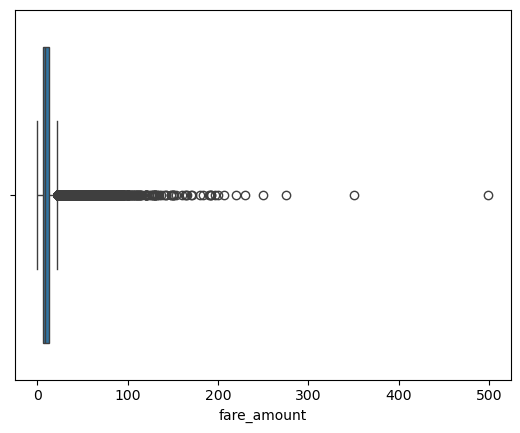

In [29]:
sns.boxplot(x=df["fare_amount"])
plt.show()

In [30]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print(lower)
print (upper)


-3.75
22.25


In [31]:
df = df[
    (df["fare_amount"] >= lower) &
    (df["fare_amount"] <= upper)
]

df.shape

(182822, 6)

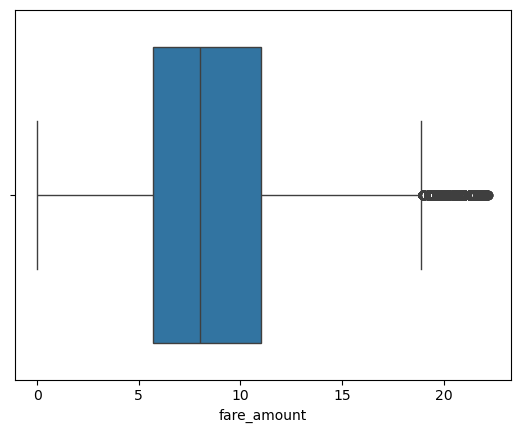

In [32]:
sns.boxplot(x=df["fare_amount"])
plt.show()

In [33]:
def haversine(lon1, lon2, lat1, lat2):
    lon1, lon2, lat1, lat2 = np.radians([lon1, lon2, lat1, lat2])

    diff_lat = lat2 - lat1
    diff_lon = lon2 - lon1

    a = np.sin(diff_lat / 2)**2
    b = np.cos(lat1) * np.cos(lat2) * np.sin(diff_lon / 2)**2

    return 2 * 6371 * np.arcsin(np.sqrt(a + b))

In [34]:
df["Distance"] = haversine(
    df["pickup_longitude"],
    df["dropoff_longitude"],
    df["pickup_latitude"],
    df["dropoff_latitude"]
)

In [35]:
Q1 = df["Distance"].quantile(0.25)
Q3 = df["Distance"].quantile(0.75)

IQR = Q3 - Q1

df = df[
    (df["Distance"] >= Q1 - 1.5 * IQR) &
    (df["Distance"] <= Q3 + 1.5 * IQR)
].copy()

print(df["Distance"].describe())

count    174530.000000
mean          2.218845
std           1.454700
min           0.000000
25%           1.131362
50%           1.876612
75%           3.030334
max           6.463099
Name: Distance, dtype: float64


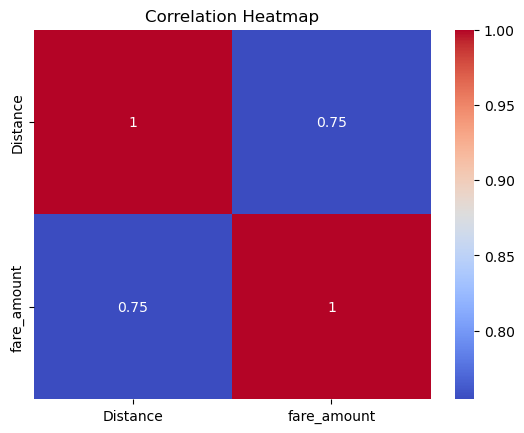

In [36]:
sns.heatmap(
    df[["Distance", "fare_amount"]].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

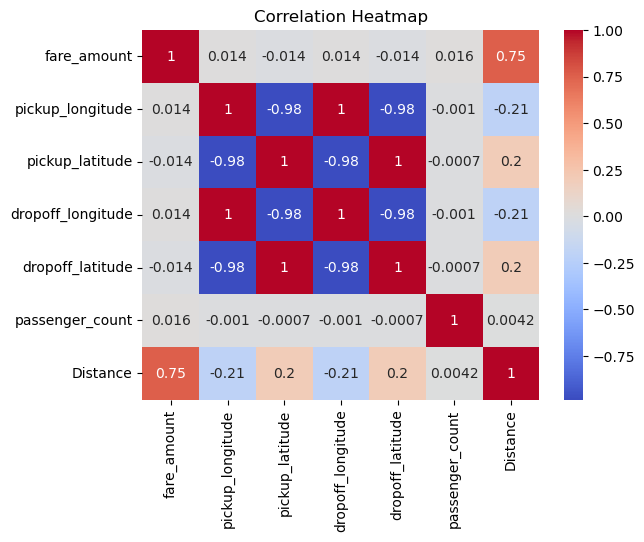

In [37]:

sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [41]:
X = df.drop('fare_amount', axis=1)
y = df['fare_amount']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


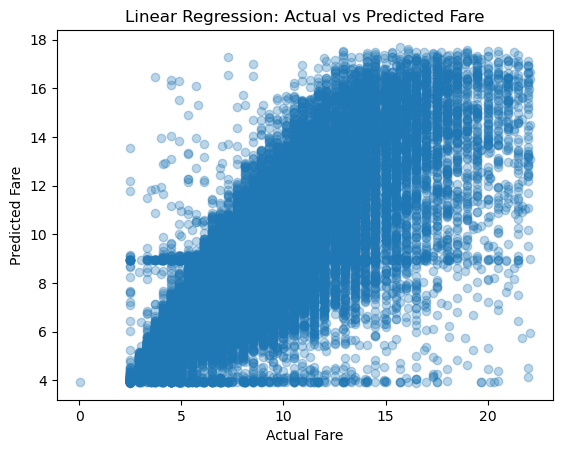

In [42]:
# Linear Regression
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)
pred1 = lr.predict(X_test)

plt.scatter(y_test, pred1, alpha=0.3)
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Linear Regression: Actual vs Predicted Fare")
plt.show()

In [43]:
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)
print("\nLINEAR REGRESSION")
print("R2 Score:", r2_score(y_test, pred1))
print("MAE:", mean_absolute_error(y_test, pred1))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred1)))


LINEAR REGRESSION
R2 Score: 0.6141604048183462
MAE: 1.6835197047520514
RMSE: 2.3385780713239703


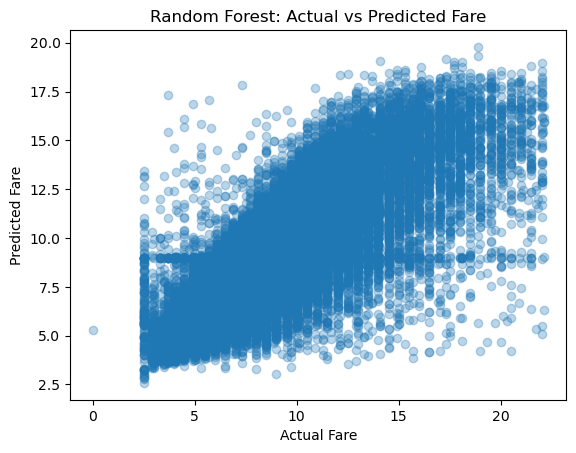

In [45]:
#random forest
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=50, random_state=42)
rf.fit(X_train, y_train)
pred2 = rf.predict(X_test)

plt.scatter(y_test, pred2, alpha=0.3)
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Random Forest: Actual vs Predicted Fare")
plt.show()

In [46]:
print("\nrandom forest")
print("R2 Score:", r2_score(y_test, pred2))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred2)))
print("MAE:", mean_absolute_error(y_test, pred2))


random forest
R2 Score: 0.6598375184232899
RMSE: 2.1957944445460567
MAE: 1.5501372086630434


In [47]:
comparison = pd.DataFrame({
    "Actual Fare": y_test.values,
    "Predicted Fare": pred2
})

comparison.head(10)

,Actual Fare,Predicted Fare
0,12.5,14.400000
1,16.9,13.596000
2,7.3,9.304000
3,10.0,10.926000
4,8.0,5.652000
5,6.9,8.694103
6,7.7,10.182000
7,11.5,11.646000
8,8.0,7.770000
9,4.9,5.520000


In [48]:
comparison = pd.DataFrame({
    "Actual Fare": y_test.values,
    "Predicted Fare": pred1
})

comparison.head(10)

,Actual Fare,Predicted Fare
0,12.5,13.613457
1,16.9,12.799190
2,7.3,8.540055
3,10.0,9.838854
4,8.0,5.106332
5,6.9,9.093100
6,7.7,9.977762
7,11.5,12.417870
8,8.0,7.989960
9,4.9,6.188834


In [279]:
print(df[["Distance", "fare_amount"]].describe())
print(df[["Distance", "fare_amount"]].corr())
print("Pickup coordinates:")
print(df[["pickup_latitude", "pickup_longitude"]].head())

            Distance    fare_amount
count  174530.000000  174530.000000
mean        2.218845       8.550199
std         1.454700       3.728559
min         0.000000       0.010000
25%         1.131362       5.700000
50%         1.876612       7.700000
75%         3.030334      10.500000
max         6.463099      22.100000
             Distance  fare_amount
Distance     1.000000     0.754568
fare_amount  0.754568     1.000000
Pickup coordinates:
   pickup_latitude  pickup_longitude
0        40.738354        -73.999817
1        40.728225        -73.994355
2        40.740770        -74.005043
3        40.790844        -73.976124
4        40.744085        -73.925023
